# English → Urdu Neural Machine Translation
**Name:** Mohammad Ibrahim Salman  
**Roll Number:** 23L-0723  
**Course:** Natural Language Processing

**NLP Assignment 3**: RNN, BiRNN, LSTM, BiLSTM and Transformer encoder-decoder models, plus
random vs. pre-trained GloVe embeddings for the RNN model.

Dataset: [Parallel corpus for English & Urdu](https://www.kaggle.com/datasets/zainuddin123/parallel-corpus-for-english-urdu-language)
(24,525 sentence pairs).

All models share the same core configuration: the same vocabulary, padding length, embedding size, hidden size,
optimiser, learning rate, batch size, loss, gradient clipping, number of epochs (50) and greedy decoding.

In [1]:
import os, re, glob, json, math, time, random, collections
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
import matplotlib.pyplot as plt
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

# ---- Shared configuration (identical for every model) ----
CFG = dict(
    MAX_VOCAB=6000,      # vocabulary cap, same for English and Urdu and for every model
    MAX_LEN=16,          # padded length for input and output (incl. <sos>/<eos> on the target)
    EMB_DIM=200,         # matches GloVe 6B 200d
    HIDDEN=256,          # RNN hidden size / Transformer feed-forward input
    LAYERS=2,            # encoder & decoder layers (RNN layers / Transformer blocks)
    N_HEADS=8,           # Transformer attention heads
    FF_DIM=512,          # Transformer feed-forward size
    DROPOUT=0.3,
    BATCH=64,
    LR=5e-4,
    EPOCHS=int(os.environ.get("EPOCHS", 50)),
    CLIP=1.0,
    LABEL_SMOOTHING=0.1,
)
print(CFG)
OUT = os.environ.get("OUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs")
os.makedirs(OUT, exist_ok=True)


def find_file(name):
    roots = [os.environ.get("DATA_DIR", ""), "/kaggle/input", "data", "."]
    for r in roots:
        if r and os.path.isdir(r):
            hits = glob.glob(os.path.join(r, "**", name), recursive=True)
            if hits:
                return hits[0]
    return None

Device: cpu 
{'MAX_VOCAB': 6000, 'MAX_LEN': 16, 'EMB_DIM': 200, 'HIDDEN': 256, 'LAYERS': 2, 'N_HEADS': 8, 'FF_DIM': 512, 'DROPOUT': 0.3, 'BATCH': 64, 'LR': 0.0005, 'EPOCHS': 50, 'CLIP': 1.0, 'LABEL_SMOOTHING': 0.1}


## Part 1 — Data preprocessing
### 1.1 Load the dataset with Pandas

In [2]:
en_path, ur_path = find_file("english-corpus.txt"), find_file("urdu-corpus.txt")
with open(en_path, encoding="utf-8") as f: en_lines = f.read().split("\n")
with open(ur_path, encoding="utf-8") as f: ur_lines = f.read().split("\n")
df = pd.DataFrame({"english": en_lines, "urdu": ur_lines})
df["english"] = df["english"].str.strip(); df["urdu"] = df["urdu"].str.strip()
df = df[(df.english != "") & (df.urdu != "")].reset_index(drop=True)
print(df.shape)
df.head(10)

(24524, 2)


,english,urdu
0,is zain your nephew,زین تمہارا بھتیجا ہے۔
1,i wish youd trust me,کاش تم مجھ پر بھروسہ کرتے
2,did he touch you,کیا اس نے آپ کو چھوا؟
3,its part of life,اس کی زندگی کا حصہ
4,zain isnt ugly,زین بدصورت نہیں ہے۔
5,above all be patient,سب سے بڑھ کر صبر کرو
6,i learned it from him,میں نے اسے اس سے سیکھا۔
7,why am i doing this,میں یہ کیوں کر رہا ہوں
8,i made a bad decision,میں نے ایک برا فیصلہ کیا
9,zain wont care,زین پرواہ نہیں کرے گا


### 1.2 Tokenization
* English: lower-cased, words/apostrophes kept together, punctuation split off.
* Urdu: Urdu punctuation (`۔ ؟ ،`) and Latin punctuation are separated, then whitespace split.

One vocabulary per language, both capped at the same `MAX_VOCAB` and shared by every model.
Special tokens: `<pad>=0, <sos>=1, <eos>=2, <unk>=3`.

In [3]:
def tok_en(s):
    return re.findall(r"[a-z0-9']+|[^\sa-z0-9']", s.lower())

def tok_ur(s):
    s = re.sub(r"([۔؟!،?.,\"])", r" \1 ", s)
    return s.split()

PAD, SOS, EOS, UNK = 0, 1, 2, 3
SPECIALS = ["<pad>", "<sos>", "<eos>", "<unk>"]

class Vocab:
    def __init__(self, token_lists, max_size):
        cnt = collections.Counter(t for toks in token_lists for t in toks)
        self.itos = SPECIALS + [w for w, _ in cnt.most_common(max_size - len(SPECIALS))]
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def __len__(self): return len(self.itos)
    def encode(self, toks): return [self.stoi.get(t, UNK) for t in toks]
    def decode(self, ids):
        out = []
        for i in ids:
            i = int(i)
            if i == EOS: break
            if i in (PAD, SOS): continue
            out.append(self.itos[i])
        return out

df["en_tok"] = df.english.apply(tok_en)
df["ur_tok"] = df.urdu.apply(tok_ur)
print(df[["english", "en_tok", "urdu", "ur_tok"]].head(5).to_string())
print("English length stats:\n", df.en_tok.str.len().describe())
print("Urdu length stats:\n", df.ur_tok.str.len().describe())

# Fixed split: 80% train / 10% validation / 10% test
perm = np.random.RandomState(SEED).permutation(len(df))
n_tr, n_va = int(0.8 * len(df)), int(0.1 * len(df))
tr_idx, va_idx, te_idx = perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]
train_df, val_df, test_df = df.iloc[tr_idx].reset_index(drop=True), df.iloc[va_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
print(len(train_df), len(val_df), len(test_df))

# Vocabularies are built on the training split only
SRC_VOCAB = Vocab(train_df.en_tok, CFG["MAX_VOCAB"])
TGT_VOCAB = Vocab(train_df.ur_tok, CFG["MAX_VOCAB"])
print("English vocab:", len(SRC_VOCAB), "| Urdu vocab:", len(TGT_VOCAB))

                english                      en_tok                       urdu                            ur_tok
0   is zain your nephew    [is, zain, your, nephew]      زین تمہارا بھتیجا ہے۔      [زین, تمہارا, بھتیجا, ہے, ۔]
1  i wish youd trust me  [i, wish, youd, trust, me]  کاش تم مجھ پر بھروسہ کرتے  [کاش, تم, مجھ, پر, بھروسہ, کرتے]
2      did he touch you       [did, he, touch, you]      کیا اس نے آپ کو چھوا؟    [کیا, اس, نے, آپ, کو, چھوا, ؟]
3      its part of life       [its, part, of, life]         اس کی زندگی کا حصہ          [اس, کی, زندگی, کا, حصہ]
4        zain isnt ugly          [zain, isnt, ugly]        زین بدصورت نہیں ہے۔        [زین, بدصورت, نہیں, ہے, ۔]
English length stats:
 count    24524.000000
mean         4.042448
std          1.175238
min          1.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         16.000000
Name: en_tok, dtype: float64
Urdu length stats:
 count    24524.000000
mean         5.323153
std          1.798816
min     

English vocab: 5135 | Urdu vocab: 5134


### 1.3 Pad sequences to a fixed length
Source: `tokens` truncated/padded to `MAX_LEN`. Target: `<sos> tokens <eos>` truncated/padded to `MAX_LEN`.

In [4]:
L = CFG["MAX_LEN"]

def pad_src(toks):
    ids = SRC_VOCAB.encode(toks)[:L]
    return ids + [PAD] * (L - len(ids))

def pad_tgt(toks):
    ids = [SOS] + TGT_VOCAB.encode(toks)[:L - 2] + [EOS]
    return ids + [PAD] * (L - len(ids))

def to_tensors(d):
    return (torch.tensor([pad_src(t) for t in d.en_tok]), torch.tensor([pad_tgt(t) for t in d.ur_tok]))

Xtr, Ytr = to_tensors(train_df); Xva, Yva = to_tensors(val_df); Xte, Yte = to_tensors(test_df)
print("Padded shapes:", Xtr.shape, Ytr.shape)
print("Example:", train_df.english[0], "->", Xtr[0].tolist())
print("        ", train_df.urdu[0], "->", Ytr[0].tolist())

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(Xtr, Ytr), batch_size=CFG["BATCH"], shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(Xva, Yva), batch_size=256)

Padded shapes: torch.Size([19619, 16]) torch.Size([19619, 16])


Example: are they brothers -> [14, 35, 839, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
         کیا وہ بھائی ہیں؟ -> [1, 9, 12, 281, 15, 22, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Part 2 — Model implementations
### Recurrent encoder-decoder (RNN / BiRNN / LSTM / BiLSTM)
* **Encoder**: embedding → `LAYERS`-layer RNN or LSTM (optionally bidirectional), packed so padding is ignored.
  For the bidirectional encoders the forward and backward final states of each layer are concatenated and
  projected (Linear + tanh) to the decoder hidden size.
* **Decoder**: unidirectional RNN/LSTM of the same type. Following Cho et al. (2014), the encoder's
  top-layer context vector is concatenated with the decoder input at every step and with the decoder output
  before the final vocabulary projection. These models do **not** use attention, so the whole source sentence
  has to pass through one fixed-size vector.
* Training uses teacher forcing; inference uses greedy decoding.

In [5]:
class RNNEncoder(nn.Module):
    def __init__(self, vocab, cell, bidirectional, pretrained=None):
        super().__init__()
        E, H, NL = CFG["EMB_DIM"], CFG["HIDDEN"], CFG["LAYERS"]
        self.cell, self.bi, self.NL, self.H = cell, bidirectional, NL, H
        self.emb = nn.Embedding(vocab, E, padding_idx=PAD)
        if pretrained is not None:
            self.emb.weight.data.copy_(pretrained)
        RNN = nn.LSTM if cell == "lstm" else nn.RNN
        self.rnn = RNN(E, H, NL, batch_first=True, dropout=CFG["DROPOUT"], bidirectional=bidirectional)
        self.drop = nn.Dropout(CFG["DROPOUT"])
        if bidirectional:
            self.proj_h = nn.Linear(2 * H, H)
            if cell == "lstm":
                self.proj_c = nn.Linear(2 * H, H)

    def _merge(self, s, proj):  # s: (NL*2, B, H) -> (NL, B, H)
        s = s.view(self.NL, 2, s.size(1), self.H)
        return torch.tanh(proj(torch.cat([s[:, 0], s[:, 1]], dim=-1)))

    def forward(self, src):
        lengths = (src != PAD).sum(1).clamp(min=1).cpu()
        x = self.drop(self.emb(src))
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, state = self.rnn(packed)
        if self.cell == "lstm":
            h, c = state
            if self.bi: h, c = self._merge(h, self.proj_h), self._merge(c, self.proj_c)
            return (h, c), h[-1]
        h = state
        if self.bi: h = self._merge(h, self.proj_h)
        return h, h[-1]


class RNNDecoder(nn.Module):
    def __init__(self, vocab, cell):
        super().__init__()
        E, H, NL = CFG["EMB_DIM"], CFG["HIDDEN"], CFG["LAYERS"]
        self.emb = nn.Embedding(vocab, E, padding_idx=PAD)
        RNN = nn.LSTM if cell == "lstm" else nn.RNN
        self.rnn = RNN(E + H, H, NL, batch_first=True, dropout=CFG["DROPOUT"])
        self.drop = nn.Dropout(CFG["DROPOUT"])
        self.out = nn.Linear(2 * H, vocab)

    def forward(self, tgt_in, state, ctx):  # tgt_in (B,T), ctx (B,H)
        x = self.drop(self.emb(tgt_in))
        c = ctx.unsqueeze(1).expand(-1, x.size(1), -1)
        o, state = self.rnn(torch.cat([x, c], -1), state)
        return self.out(self.drop(torch.cat([o, c], -1))), state


class Seq2SeqRNN(nn.Module):
    def __init__(self, cell="rnn", bidirectional=False, pretrained=None):
        super().__init__()
        self.enc = RNNEncoder(len(SRC_VOCAB), cell, bidirectional, pretrained)
        self.dec = RNNDecoder(len(TGT_VOCAB), cell)

    def forward(self, src, tgt_in):
        state, ctx = self.enc(src)
        logits, _ = self.dec(tgt_in, state, ctx)
        return logits

    @torch.no_grad()
    def greedy(self, src, max_len=L):
        state, ctx = self.enc(src)
        tok = torch.full((src.size(0), 1), SOS, dtype=torch.long, device=src.device)
        outs = []
        for _ in range(max_len - 1):
            logits, state = self.dec(tok, state, ctx)
            tok = logits.argmax(-1)
            outs.append(tok)
        return torch.cat(outs, 1)

### Transformer encoder-decoder (multi-head attention)
Sinusoidal positional encoding + `nn.Transformer` (`LAYERS` encoder and decoder blocks, `N_HEADS` heads,
`d_model = EMB_DIM`), with padding masks and a causal mask on the decoder.

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d, max_len=64):
        super().__init__()
        pe = torch.zeros(max_len, d)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]


class Seq2SeqTransformer(nn.Module):
    def __init__(self, pretrained=None):
        super().__init__()
        d = CFG["EMB_DIM"]
        self.d = d
        self.src_emb = nn.Embedding(len(SRC_VOCAB), d, padding_idx=PAD)
        if pretrained is not None:
            self.src_emb.weight.data.copy_(pretrained)
        self.tgt_emb = nn.Embedding(len(TGT_VOCAB), d, padding_idx=PAD)
        self.pos = PositionalEncoding(d)
        self.drop = nn.Dropout(CFG["DROPOUT"])
        self.tf = nn.Transformer(d_model=d, nhead=CFG["N_HEADS"], num_encoder_layers=CFG["LAYERS"],
                                 num_decoder_layers=CFG["LAYERS"], dim_feedforward=CFG["FF_DIM"],
                                 dropout=CFG["DROPOUT"], batch_first=True)
        self.out = nn.Linear(d, len(TGT_VOCAB))

    def encode(self, src):
        mask = src == PAD
        return self.tf.encoder(self.drop(self.pos(self.src_emb(src) * math.sqrt(self.d))), src_key_padding_mask=mask), mask

    def decode(self, tgt_in, mem, src_mask):
        T = tgt_in.size(1)
        causal = torch.triu(torch.full((T, T), float("-inf"), device=tgt_in.device), 1)
        y = self.drop(self.pos(self.tgt_emb(tgt_in) * math.sqrt(self.d)))
        h = self.tf.decoder(y, mem, tgt_mask=causal, tgt_key_padding_mask=tgt_in == PAD,
                            memory_key_padding_mask=src_mask)
        return self.out(h)

    def forward(self, src, tgt_in):
        mem, m = self.encode(src)
        return self.decode(tgt_in, mem, m)

    @torch.no_grad()
    def greedy(self, src, max_len=L):
        mem, m = self.encode(src)
        ys = torch.full((src.size(0), 1), SOS, dtype=torch.long, device=src.device)
        for _ in range(max_len - 1):
            nxt = self.decode(ys, mem, m)[:, -1].argmax(-1, keepdim=True)
            ys = torch.cat([ys, nxt], 1)
        return ys[:, 1:]

### Shared training loop
Adam (lr `LR`), cross-entropy with label smoothing (padding ignored), gradient clipping, `EPOCHS` epochs, and
teacher forcing. The weights with the lowest validation loss are kept for evaluation.

In [7]:
def run_epoch(model, loader, opt=None):
    train = opt is not None
    model.train(train)
    crit = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=CFG["LABEL_SMOOTHING"])
    tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for src, tgt in loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            logits = model(src, tgt[:, :-1])
            loss = crit(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"]); opt.step()
            tot += loss.item() * src.size(0); n += src.size(0)
    return tot / n


def train_model(name, model):
    torch.manual_seed(SEED)
    model = model.to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n=== {name}: {n_params:,} trainable parameters ===")
    opt = torch.optim.Adam(model.parameters(), lr=CFG["LR"])
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best, best_state, best_ep = float("inf"), None, 0
    t0 = time.time()
    for ep in range(1, CFG["EPOCHS"] + 1):
        te = time.time()
        tl = run_epoch(model, train_loader, opt)
        vl = run_epoch(model, val_loader)
        hist["train_loss"].append(tl); hist["val_loss"].append(vl); hist["epoch_time"].append(time.time() - te)
        if vl < best:
            best, best_ep = vl, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ep == 1 or ep % 5 == 0:
            print(f"epoch {ep:3d} | train {tl:.4f} | val {vl:.4f} | {hist['epoch_time'][-1]:.1f}s")
    hist.update(total_time=time.time() - t0, best_val=best, best_epoch=best_ep, params=n_params)
    model.load_state_dict(best_state)
    print(f"{name}: best val loss {best:.4f} at epoch {best_ep}, total {hist['total_time']:.0f}s")
    return model, hist

### Evaluation metrics
* **BLEU** (corpus-level BLEU-4, NLTK, with smoothing) on Urdu word tokens.
* **ROUGE-1 / ROUGE-2 / ROUGE-L F1**: implemented here on word tokens, because the common `rouge_score`
  package's default tokenizer drops non-Latin characters and would score every Urdu sentence as 0.
* **METEOR** (NLTK) on word tokens. There is no Urdu WordNet, so only exact and stem matches count
  (plus the fragmentation penalty).
* **chrF** (character n-gram F-score) as a check that does not depend on how words are tokenized.

In [8]:
# English WordNet synonyms do not apply to Urdu, so METEOR gets an empty synonym source.
# This also means no WordNet download is needed.
class _NoWordNet:
    def synsets(self, *a, **k): return []
try:
    from nltk.translate.meteor_score import meteor_score
    meteor_score([["a", "b"]], ["c"], wordnet=_NoWordNet())
    HAS_METEOR = True
except Exception as e:
    print("METEOR unavailable:", e); HAS_METEOR = False

def ngrams(t, n): return collections.Counter(tuple(t[i:i + n]) for i in range(len(t) - n + 1))

def rouge_n(ref, hyp, n):
    r, h = ngrams(ref, n), ngrams(hyp, n)
    ov = sum((r & h).values())
    if not r or not h or ov == 0: return 0.0
    p, rc = ov / sum(h.values()), ov / sum(r.values())
    return 2 * p * rc / (p + rc)

def lcs(a, b):
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b, 1):
            cur = dp[j]
            dp[j] = prev + 1 if x == y else max(dp[j], dp[j - 1])
            prev = cur
    return dp[-1]

def rouge_l(ref, hyp):
    if not ref or not hyp: return 0.0
    l = lcs(ref, hyp)
    if l == 0: return 0.0
    p, r = l / len(hyp), l / len(ref)
    return 2 * p * r / (p + r)

def chrf(refs, hyps, n=6, beta=2):
    scores = []
    for r, h in zip(refs, hyps):
        r, h = "".join(r), "".join(h)  # characters without spaces
        ps, rs = [], []
        for k in range(1, n + 1):
            rc, hc = ngrams(r, k), ngrams(h, k)
            ov = sum((rc & hc).values())
            if sum(hc.values()): ps.append(ov / sum(hc.values()))
            if sum(rc.values()): rs.append(ov / sum(rc.values()))
        p, rr = (np.mean(ps) if ps else 0), (np.mean(rs) if rs else 0)
        scores.append(0 if p + rr == 0 else (1 + beta ** 2) * p * rr / (beta ** 2 * p + rr))
    return float(np.mean(scores))

def evaluate(refs, hyps):
    sm = SmoothingFunction().method1
    res = {
        "BLEU": 100 * corpus_bleu([[r] for r in refs], hyps, smoothing_function=sm),
        "BLEU-1": 100 * corpus_bleu([[r] for r in refs], hyps, weights=(1, 0, 0, 0), smoothing_function=sm),
        "ROUGE-1": 100 * np.mean([rouge_n(r, h, 1) for r, h in zip(refs, hyps)]),
        "ROUGE-2": 100 * np.mean([rouge_n(r, h, 2) for r, h in zip(refs, hyps)]),
        "ROUGE-L": 100 * np.mean([rouge_l(r, h) for r, h in zip(refs, hyps)]),
        "chrF": 100 * chrf(refs, hyps),
    }
    if HAS_METEOR:
        res["METEOR"] = 100 * np.mean([meteor_score([r], h, wordnet=_NoWordNet()) for r, h in zip(refs, hyps)])
    return res


def translate(model, X, bs=256):
    model.eval(); outs = []
    for i in range(0, len(X), bs):
        ids = model.greedy(X[i:i + bs].to(DEVICE)).cpu()
        outs += [TGT_VOCAB.decode(r) for r in ids]
    return outs

TEST_REFS = [t for t in test_df.ur_tok]

### GloVe embeddings (for Part 4)
Embedding matrix for the English vocabulary from `glove.6B.200d.txt`. Words not found in GloVe (and `<sos>`,
`<eos>`, `<unk>`) get small random vectors; `<pad>` is zero. The embeddings are fine-tuned during training.

In [9]:
def load_glove():
    path = find_file("glove.6B.200d.txt")
    if path is None:
        print("GloVe file not found"); return None, 0.0
    rng = np.random.RandomState(SEED)
    M = rng.normal(0, 0.1, (len(SRC_VOCAB), CFG["EMB_DIM"])).astype(np.float32)
    M[PAD] = 0
    found = 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            w, rest = line.split(" ", 1)
            i = SRC_VOCAB.stoi.get(w)
            if i is not None and i >= len(SPECIALS):
                M[i] = np.asarray(rest.split(), dtype=np.float32); found += 1
    cov = found / (len(SRC_VOCAB) - len(SPECIALS))
    print(f"GloVe coverage: {found}/{len(SRC_VOCAB) - len(SPECIALS)} = {cov:.1%}")
    return torch.tensor(M), cov

GLOVE, GLOVE_COV = load_glove()

GloVe coverage: 5037/5131 = 98.2%


## Train all models
Each model is trained separately with the same configuration. The plain RNN (random embeddings) is also the
baseline for Part 4.

In [10]:
MODELS = {
    "RNN": lambda: Seq2SeqRNN("rnn", False),
    "BiRNN": lambda: Seq2SeqRNN("rnn", True),
    "LSTM": lambda: Seq2SeqRNN("lstm", False),
    "BiLSTM": lambda: Seq2SeqRNN("lstm", True),
    "Transformer": lambda: Seq2SeqTransformer(),
}
if GLOVE is not None:
    MODELS["RNN + GloVe"] = lambda: Seq2SeqRNN("rnn", False, pretrained=GLOVE)

ONLY = os.environ.get("ONLY_MODELS")
if ONLY:
    MODELS = {k: v for k, v in MODELS.items() if k in ONLY.split(",")}

# If PRETRAINED_DIR is set, reuse weights and training histories saved by an earlier full run
# (e.g. the Kaggle GPU run) instead of training again; evaluation below still runs on them.
PRETRAINED_DIR = os.environ.get("PRETRAINED_DIR")
histories, scores, translations = {}, {}, {}
for name, build in MODELS.items():
    torch.manual_seed(SEED)
    if PRETRAINED_DIR:
        model = build().to(DEVICE)
        model.load_state_dict(torch.load(os.path.join(PRETRAINED_DIR, f"{name.replace(' + ', '_').lower()}.pt"), map_location=DEVICE))
        hist = {k: v for k, v in json.load(open(os.path.join(PRETRAINED_DIR, "results.json")))["histories"][name].items()
                if k != "inference_time"}
        print(f"{name}: loaded trained weights (best val loss {hist['best_val']:.4f} at epoch {hist['best_epoch']}, "
              f"trained {len(hist['val_loss'])} epochs in {hist['total_time']:.0f}s on GPU)")
    else:
        model, hist = train_model(name, build())
    histories[name] = hist
    t = time.time()
    hyps = translate(model, Xte)
    hist["inference_time"] = time.time() - t
    translations[name] = hyps
    scores[name] = evaluate(TEST_REFS, hyps)
    print(name, {k: round(v, 2) for k, v in scores[name].items()})
    torch.save(model.state_dict(), os.path.join(OUT, f"{name.replace(' + ', '_').lower()}.pt"))
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

RNN: loaded trained weights (best val loss 2.8854 at epoch 48, trained 50 epochs in 162s on GPU)


RNN {'BLEU': 32.76, 'BLEU-1': 59.74, 'ROUGE-1': np.float64(60.93), 'ROUGE-2': np.float64(38.82), 'ROUGE-L': np.float64(60.59), 'chrF': 49.04, 'METEOR': np.float64(52.71)}
BiRNN: loaded trained weights (best val loss 2.8819 at epoch 49, trained 50 epochs in 177s on GPU)


BiRNN {'BLEU': 33.07, 'BLEU-1': 59.73, 'ROUGE-1': np.float64(61.14), 'ROUGE-2': np.float64(39.44), 'ROUGE-L': np.float64(60.77), 'chrF': 49.33, 'METEOR': np.float64(52.81)}
LSTM: loaded trained weights (best val loss 2.7471 at epoch 48, trained 50 epochs in 212s on GPU)


LSTM {'BLEU': 37.78, 'BLEU-1': 64.4, 'ROUGE-1': np.float64(64.92), 'ROUGE-2': np.float64(43.8), 'ROUGE-L': np.float64(64.42), 'chrF': 54.04, 'METEOR': np.float64(57.52)}
BiLSTM: loaded trained weights (best val loss 2.7896 at epoch 29, trained 50 epochs in 246s on GPU)


BiLSTM {'BLEU': 37.22, 'BLEU-1': 63.95, 'ROUGE-1': np.float64(64.45), 'ROUGE-2': np.float64(42.99), 'ROUGE-L': np.float64(64.07), 'chrF': 53.0, 'METEOR': np.float64(56.77)}
Transformer: loaded trained weights (best val loss 2.8241 at epoch 50, trained 50 epochs in 289s on GPU)


/usr/local/lib/python3.13/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(
/usr/local/lib/python3.13/site-packages/torch/nn/modules/activation.py:1337: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


/usr/local/lib/python3.13/site-packages/torch/nn/modules/activation.py:1337: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Transformer {'BLEU': 39.7, 'BLEU-1': 65.08, 'ROUGE-1': np.float64(65.75), 'ROUGE-2': np.float64(45.54), 'ROUGE-L': np.float64(65.12), 'chrF': 56.99, 'METEOR': np.float64(58.8)}
RNN + GloVe: loaded trained weights (best val loss 2.7846 at epoch 48, trained 50 epochs in 161s on GPU)


RNN + GloVe {'BLEU': 35.32, 'BLEU-1': 62.28, 'ROUGE-1': np.float64(63.19), 'ROUGE-2': np.float64(41.16), 'ROUGE-L': np.float64(62.79), 'chrF': 51.24, 'METEOR': np.float64(55.31)}


## Part 3 — Evaluation and comparison
### 3.1 Final scores on the held-out test set (10% of the corpus, never seen during training)

In [11]:
rows = []
for name in MODELS:
    h = histories[name]
    rows.append({"Model": name, **{k: round(v, 2) for k, v in scores[name].items()},
                 "Best val loss": round(h["best_val"], 4), "Best epoch": h["best_epoch"],
                 "Params": h["params"], "Train time (s)": round(h["total_time"], 1),
                 "s/epoch": round(float(np.mean(h["epoch_time"])), 2)})
results = pd.DataFrame(rows).set_index("Model")
results.to_csv(os.path.join(OUT, "results.csv"))
print(results.to_string())
results

              BLEU  BLEU-1  ROUGE-1  ROUGE-2  ROUGE-L   chrF  METEOR  Best val loss  Best epoch   Params  Train time (s)  s/epoch
Model                                                                                                                            
RNN          32.76   59.74    60.93    38.82    60.59  49.04   52.71         2.8854          48  5250742           161.6     3.23
BiRNN        33.07   59.73    61.14    39.44    60.77  49.33   52.81         2.8819          49  5761974           176.8     3.54
LSTM         37.78   64.40    64.92    43.80    64.42  54.04   57.52         2.7471          48  6940342           211.7     4.23
BiLSTM       37.22   63.95    64.45    42.99    64.07  53.00   56.77         2.7896          29  8722614           246.3     4.93
Transformer  39.70   65.08    65.75    45.54    65.12  56.99   58.80         2.8241          50  4877382           288.9     5.78
RNN + GloVe  35.32   62.28    63.19    41.16    62.79  51.24   55.31         2.7846       

,BLEU,BLEU-1,ROUGE-1,ROUGE-2,ROUGE-L,chrF,METEOR,Best val loss,Best epoch,Params,Train time (s),s/epoch
Model,,,,,,,,,,,,
RNN,32.76,59.74,60.93,38.82,60.59,49.04,52.71,2.8854,48,5250742,161.6,3.23
BiRNN,33.07,59.73,61.14,39.44,60.77,49.33,52.81,2.8819,49,5761974,176.8,3.54
LSTM,37.78,64.40,64.92,43.80,64.42,54.04,57.52,2.7471,48,6940342,211.7,4.23
BiLSTM,37.22,63.95,64.45,42.99,64.07,53.00,56.77,2.7896,29,8722614,246.3,4.93
Transformer,39.70,65.08,65.75,45.54,65.12,56.99,58.80,2.8241,50,4877382,288.9,5.78
RNN + GloVe,35.32,62.28,63.19,41.16,62.79,51.24,55.31,2.7846,48,5250742,160.8,3.22


### 3.2 Inference examples: a fixed set of test sentences translated by every model

In [12]:
FIXED = list(range(0, len(test_df), max(1, len(test_df) // 15)))[:15]
ex = pd.DataFrame({"English": test_df.english.iloc[FIXED].values, "Reference": test_df.urdu.iloc[FIXED].values})
for name in MODELS:
    ex[name] = [" ".join(translations[name][i]) for i in FIXED]
ex.to_csv(os.path.join(OUT, "sample_translations.csv"), index=False)
pd.set_option("display.max_colwidth", 60)
for i in range(len(ex)):
    print(f"\nEN : {ex.English[i]}\nREF: {ex.Reference[i]}")
    for name in MODELS:
        print(f"  {name:12s}: {ex[name][i]}")

# Also translate some hand-written sentences that are not in the dataset
CUSTOM = ["i am happy", "where is my book", "he is a good boy", "what is your name", "we are going home"]
Xc = torch.tensor([pad_src(tok_en(s)) for s in CUSTOM])
custom_out = {"English": CUSTOM}
for name, build in MODELS.items():
    m = build().to(DEVICE)
    m.load_state_dict(torch.load(os.path.join(OUT, f"{name.replace(' + ', '_').lower()}.pt"), map_location=DEVICE))
    custom_out[name] = [" ".join(t) for t in translate(m, Xc)]
custom_df = pd.DataFrame(custom_out)
custom_df.to_csv(os.path.join(OUT, "custom_translations.csv"), index=False)
print(custom_df.to_string())


EN : he is an italian
REF: وہ ایک اطالوی ہے
  RNN         : وہ ایک excon ہے
  BiRNN       : وہ ایک انگریز ہے
  LSTM        : وہ ایک ماہر ہے
  BiLSTM      : وہ ایک ماہر ہے
  Transformer : وہ ایک اطالوی ہے
  RNN + GloVe : وہ ایک فرانسیسی ہے

EN : whose land is this
REF: جس کی زمین یہ ہے
  RNN         : یہ کس کا ہے
  BiRNN       : یہ کس کا گٹار ہے
  LSTM        : یہ کس کی پنسل ہے
  BiLSTM      : یہ کس کی قمیض ہے ؟
  Transformer : یہ کس کا مالک ہے
  RNN + GloVe : یہ کس کا گٹار ہے

EN : zain is seldom home
REF: زین شاذ و نادر ہی گھر ہوتا ہے۔
  RNN         : زین گھر گھر ہے
  BiRNN       : زین گھر سے گھر ہے ۔
  LSTM        : زین گھر سے گھر ہے ۔
  BiLSTM      : زین گھر سے گھر ہے ۔
  Transformer : زین شاذ و نادر ہی گھر ہے ۔
  RNN + GloVe : زین گھر سے گھر ہے ۔

EN : i need a new bicycle
REF: مجھے ایک نئی سائیکل چاہیے
  RNN         : مجھے ایک نئی سائیکل چاہیے
  BiRNN       : مجھے ایک نئی سائیکل چاہیے
  LSTM        : میں ایک نئی سائیکل کی ضرورت ہے
  BiLSTM      : میں ایک نئی الماری کی ضرورت ہے
  

             English                  RNN                BiRNN                 LSTM                 BiLSTM          Transformer          RNN + GloVe
0         i am happy          میں خوش ہوں          میں خوش ہوں          میں خوش ہوں            میں خوش ہوں          میں خوش ہوں          میں خوش ہوں
1   where is my book  میری کتاب کہاں ہے ؟    میری کتاب کہاں ہے  میری کتاب کہاں ہے ؟    میری کتاب کہاں ہے ؟    میری کتاب کہاں ہے  میری کتاب کہاں ہے ؟
2   he is a good boy  وہ ایک اچھا لڑکا ہے  وہ ایک اچھا لڑکا ہے    وہ اچھا لڑکا ہے ۔  وہ ایک اچھا لڑکا ہے ۔  وہ ایک اچھا لڑکا ہے  وہ ایک اچھا لڑکا ہے
3  what is your name                 ہائے                 ہائے                 ہائے                   ہائے     آپ کا نام کیا ہے                 ہائے
4  we are going home    ہم گھر جا رہے ہیں    ہم گھر جا رہے ہیں    ہم گھر جا رہے ہیں      ہم گھر جا رہے ہیں    ہم گھر جا رہے ہیں    ہم گھر جا رہے ہیں


/usr/local/lib/python3.13/site-packages/torch/nn/modules/activation.py:1337: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


### 3.3 Visualisation

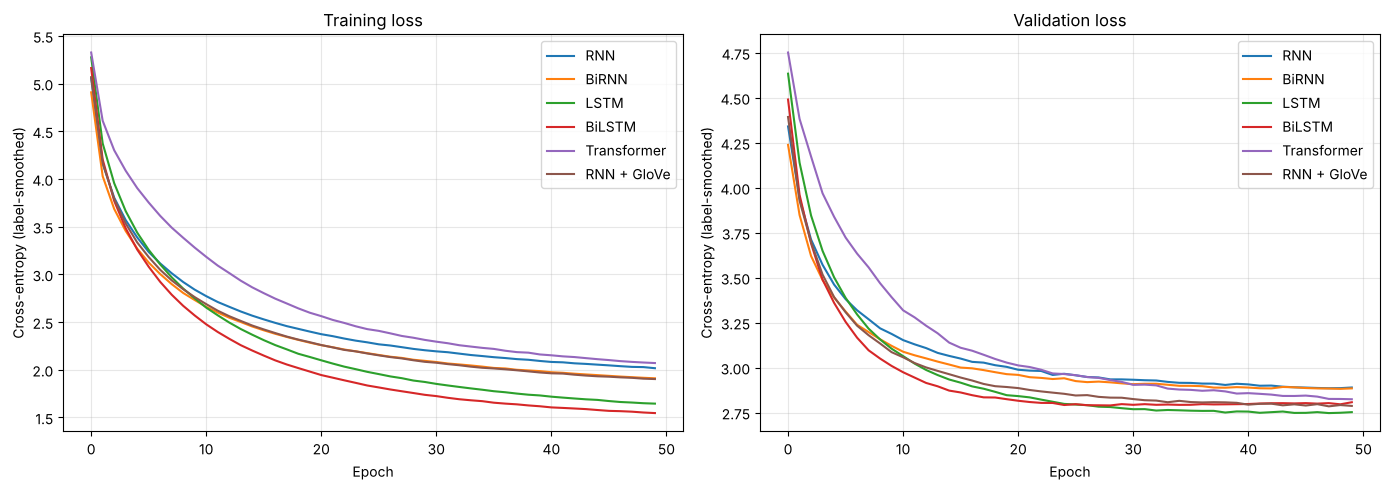

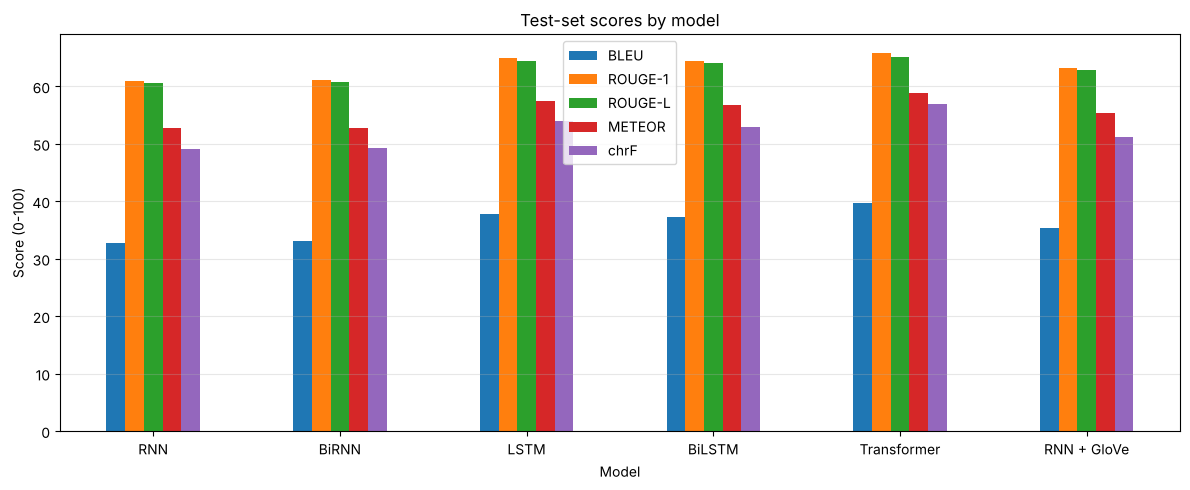

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in MODELS:
    axes[0].plot(histories[name]["train_loss"], label=name)
    axes[1].plot(histories[name]["val_loss"], label=name)
for ax, t in zip(axes, ["Training loss", "Validation loss"]):
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy (label-smoothed)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "loss_curves.png"), dpi=120); plt.show()

metrics = [m for m in ["BLEU", "ROUGE-1", "ROUGE-L", "METEOR", "chrF"] if m in results.columns]
ax = results[metrics].plot.bar(figsize=(12, 5), rot=0)
ax.set_title("Test-set scores by model"); ax.set_ylabel("Score (0-100)"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "scores.png"), dpi=120); plt.show()

## Part 4 — Random vs. pre-trained GloVe embeddings (RNN model)

              BLEU  BLEU-1  ROUGE-1  ROUGE-2  ROUGE-L   chrF  METEOR  Best val loss  Best epoch   Params  Train time (s)  s/epoch
Model                                                                                                                            
RNN          32.76   59.74    60.93    38.82    60.59  49.04   52.71         2.8854          48  5250742           161.6     3.23
RNN + GloVe  35.32   62.28    63.19    41.16    62.79  51.24   55.31         2.7846          48  5250742           160.8     3.22
First epoch reaching val loss <= 2.8854: {'RNN': 48, 'RNN + GloVe': 22}


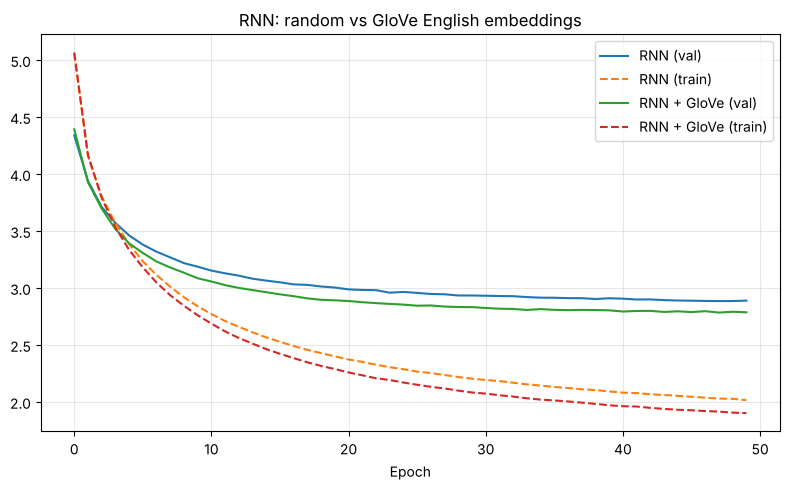

In [14]:
if "RNN + GloVe" in MODELS and "RNN" in MODELS:
    cmp = results.loc[["RNN", "RNN + GloVe"]]
    print(cmp.to_string())

    def first_epoch_below(h, thr):
        return next((i + 1 for i, v in enumerate(h["val_loss"]) if v <= thr), None)
    thr = max(histories["RNN"]["best_val"], histories["RNN + GloVe"]["best_val"])
    conv = {n: first_epoch_below(histories[n], thr) for n in ["RNN", "RNN + GloVe"]}
    print(f"First epoch reaching val loss <= {thr:.4f}:", conv)

    fig, ax = plt.subplots(figsize=(8, 5))
    for n in ["RNN", "RNN + GloVe"]:
        ax.plot(histories[n]["val_loss"], label=f"{n} (val)")
        ax.plot(histories[n]["train_loss"], "--", label=f"{n} (train)")
    ax.set_title("RNN: random vs GloVe English embeddings"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, "glove_vs_random.png"), dpi=120); plt.show()
    part4 = {"glove_coverage": GLOVE_COV, "epochs_to_common_val_loss": conv, "common_val_loss": thr}
else:
    part4 = {}

json.dump({"config": CFG, "scores": scores, "part4": part4,
           "histories": histories}, open(os.path.join(OUT, "results.json"), "w"), indent=2, default=float)